# 02 - Heaps analysis

Unlike Zipf, Heaps requires intermediate vocabulary-growth points. The final vocabulary contains only the endpoint, so this notebook streams the selected prepared JSONL once and tokenizes each review with the shared interface.

Writing vocabulary size $M=V$ and token count $T=N$, the comparison is $\log(M)=b\log(T)+\log(k)$. The assignment's empirical references are $k\in[30,100]$ and $b\approx0.5$; this notebook uses $b\in[0.40,0.60]$ and log-space $R^2\geq0.95$ as explicit descriptive guides. These are corpus- and tokenization-dependent references, not correctness tests.

In [ ]:
import json, math, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root() -> Path:
    if configured_root := os.environ.get('YELPTEXT_PROJECT_ROOT'):
        return Path(configured_root).resolve()
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'src' / 'yelptext').is_dir():
            return candidate
    raise RuntimeError('Cannot locate the project root. Start Jupyter inside this repository.')

ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from yelptext.interface.data_corpus_analysis import create_review_reader, create_tokenizer
from yelptext.runtime import load_config

CONFIG_PATH = Path(os.environ.get('YELPTEXT_CONFIG', ROOT / 'configs' / 'full.toml')).resolve()
config = load_config(CONFIG_PATH)
prepared_path = (ROOT / config['data']['prepared_path']).resolve()
fractions = sorted(set(config.get('analysis', {}).get('heaps', {}).get('sample_fractions', [0.1, 0.3, 0.5, 1.0])))
output_dir = ROOT / 'artifacts' / 'heaps'
output_dir.mkdir(parents=True, exist_ok=True)
print(f'Project root: {ROOT}')
print(f'Config:       {CONFIG_PATH}')
print(f'Prepared:     {prepared_path}')
print(f'Checkpoints:  {fractions}')

Project root: F:\1_graduates\text_management\group
Config:       F:\1_graduates\text_management\group\configs\full.toml
Prepared:     F:\1_graduates\text_management\group\data\processed\reviews-full.jsonl
Checkpoints:  [0.1, 0.3, 0.5, 1.0]


In [2]:
if not prepared_path.is_file():
    raise FileNotFoundError(
        f'{prepared_path} does not exist. Run: yelptext prepare --config {CONFIG_PATH}'
    )

with prepared_path.open('rb') as source:
    document_count = sum(bool(line.strip()) for line in source)
targets = {max(1, math.ceil(document_count * fraction)): fraction for fraction in fractions}
reader = create_review_reader(prepared_path)
tokenizer = create_tokenizer()
seen = set()
token_count = 0
points = []
for index, review in enumerate(reader.iter_reviews(), start=1):
    terms = [term for term in tokenizer.tokenize(review['text']) if term not in {'!', '?', '#'}]
    token_count += len(terms)
    seen.update(terms)
    if index in targets:
        points.append({'fraction': targets[index], 'reviews': index, 'N': token_count, 'V': len(seen)})
    if index % 100_000 == 0:
        print(f'{index:,}/{document_count:,} reviews | N={token_count:,} | V={len(seen):,}')
growth = pd.DataFrame(points)
growth

100,000/6,990,280 reviews | N=10,147,529 | V=72,307
200,000/6,990,280 reviews | N=20,334,282 | V=99,222
300,000/6,990,280 reviews | N=30,628,527 | V=120,777
400,000/6,990,280 reviews | N=41,058,402 | V=139,492
500,000/6,990,280 reviews | N=51,633,251 | V=156,482
600,000/6,990,280 reviews | N=62,224,704 | V=171,804
700,000/6,990,280 reviews | N=73,839,872 | V=186,851
800,000/6,990,280 reviews | N=83,980,223 | V=201,244
900,000/6,990,280 reviews | N=94,084,710 | V=213,877
1,000,000/6,990,280 reviews | N=104,308,497 | V=226,128
1,100,000/6,990,280 reviews | N=114,741,173 | V=238,283
1,200,000/6,990,280 reviews | N=125,119,129 | V=249,668
1,300,000/6,990,280 reviews | N=135,560,131 | V=260,258
1,400,000/6,990,280 reviews | N=147,171,096 | V=271,690
1,500,000/6,990,280 reviews | N=157,497,942 | V=282,778
1,600,000/6,990,280 reviews | N=167,576,038 | V=293,154
1,700,000/6,990,280 reviews | N=177,676,865 | V=302,632
1,800,000/6,990,280 reviews | N=188,087,956 | V=312,304
1,900,000/6,990,280 r

,fraction,reviews,N,V
0,0.1,699028,73726187,186721
1,0.3,2097084,219745070,340382
2,0.5,3495140,368198271,458237
3,1.0,6990280,734871222,685120


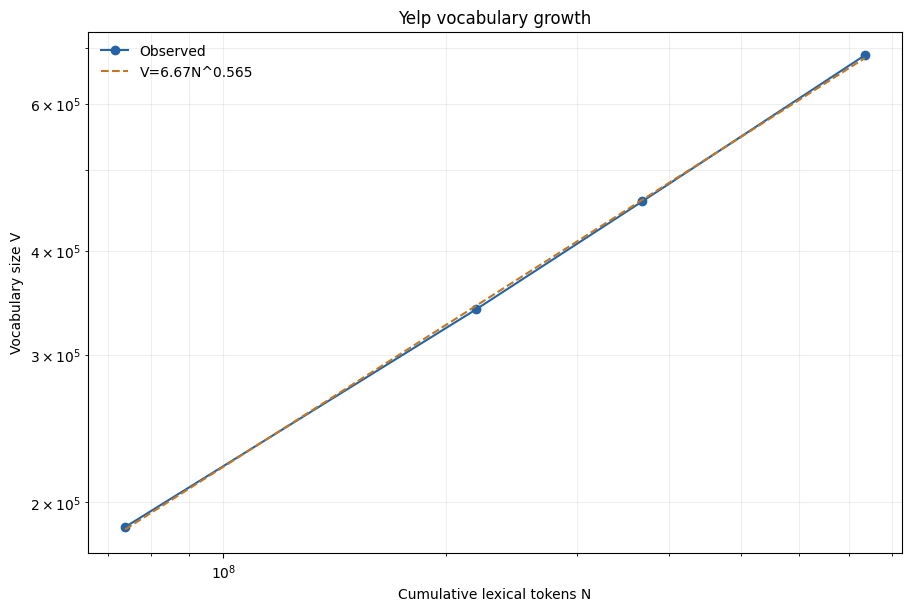

{'config': 'F:\\1_graduates\\text_management\\group\\configs\\full.toml',
 'prepared_path': 'F:\\1_graduates\\text_management\\group\\data\\processed\\reviews-full.jsonl',
 'reviews': 6990280,
 'k': 6.672142863624548,
 'beta': 0.564860859211713,
 'r_squared_log_space': 0.9997582927381885,
 'k_in_reference_range_30_100': False,
 'beta_in_reference_range_0.40_0.60': True,
 'ordering': 'prepared-file order; sample files produced by the shared sampler are in stable priority order',
 'punctuation_filter': ['!', '?', '#']}

In [5]:
slope, intercept = np.polyfit(np.log(growth['N']), np.log(growth['V']), 1)
beta = float(slope)
k = float(np.exp(intercept))
fitted_log_v = slope * np.log(growth['N']) + intercept
ss_res = float(np.sum((np.log(growth['V']) - fitted_log_v) ** 2))
ss_tot = float(np.sum((np.log(growth['V']) - np.log(growth['V']).mean()) ** 2))
r_squared = 1.0 - ss_res / ss_tot
k_in_reference_range = 30.0 <= k <= 100.0
beta_near_half = 0.40 <= beta <= 0.60
growth['fitted_V'] = k * growth['N'] ** beta
growth.to_csv(output_dir / 'heaps_growth.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 6), layout='constrained')
ax.loglog(growth['N'], growth['V'], 'o-', color='#2463A5', label='Observed')
ax.loglog(growth['N'], growth['fitted_V'], '--', color='#C37722', label=f'V={k:.3g}N^{beta:.3f}')
ax.set(xlabel='Cumulative lexical tokens N', ylabel='Vocabulary size V', title='Yelp vocabulary growth')
ax.grid(alpha=.2, which='both')
ax.legend(frameon=False)
fig.savefig(output_dir / 'heaps_loglog.png', dpi=220)
plt.show()

summary = {
    'config': str(CONFIG_PATH),
    'prepared_path': str(prepared_path),
    'reviews': document_count,
    'k': k,
    'beta': beta,
    'r_squared_log_space': r_squared,
    'k_in_reference_range_30_100': k_in_reference_range,
    'beta_in_reference_range_0.40_0.60': beta_near_half,
    'ordering': 'prepared-file order; sample files produced by the shared sampler are in stable priority order',
    'punctuation_filter': ['!', '?', '#'],
}
(output_dir / 'heaps_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
summary


INTERPRETATION

Writing vocabulary size $M=V$ and token count $T=N$, the fitted relation is
$\log(M)=b\log(T)+\log(k)$, with $k=6.672$, $b=0.565$, and
$R^2=0.9998$ in log space. Equivalently,
$M=6.672T^{0.565}$.

Against the assignment's empirical references, $k$
**falls outside $[30,100]$**
and $b$ **is close to $0.5$** under
the explicit $[0.40,0.60]$ descriptive band. The log–log curve is
**approximately linear**
by the $R^2\geq0.95$ descriptive criterion. These ranges are corpus- and
tokenization-dependent reference values rather than hard correctness tests.
This estimate uses 4 configured checkpoints, so it should be
reported as a descriptive corpus fit rather than a universal constant.